# 02 — Exploratory data analysis

**Phase 3 of Energy Intelligence.** Still no model training.

## What are we doing?

We look for **repeatable structure** in Spanish hourly demand: distribution, daily cycle, weekly cycle, seasons, and how strongly the next hour depends on recent hours.

## Why?

Those patterns tell us which features are worth engineering (hour, weekend, lags) and which years are risky as a test set (2020).

## Setup

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_rows", 20)
plt.rcParams.update(
    {
        "figure.figsize": (10, 4.2),
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlesize": 12,
        "axes.labelsize": 11,
    }
)
BRAND = "#0f766e"


def project_root() -> Path:
    here = Path.cwd()
    for candidate in (here, here.parent):
        if (candidate / "data" / "raw" / "spain_hourly_load.csv").exists():
            return candidate
    raise FileNotFoundError(
        "spain_hourly_load.csv not found. From the project root run: "
        "python scripts/download_dataset.py"
    )


ROOT = project_root()
DATA_PATH = ROOT / "data" / "raw" / "spain_hourly_load.csv"
print(f"Using {DATA_PATH}")

Using C:\Users\Hammad Ali\Energy Intelligence\data\raw\spain_hourly_load.csv


In [2]:
raw = pd.read_csv(DATA_PATH)
df = raw.copy()
df["utc"] = pd.to_datetime(df["utc_timestamp"], utc=True)
df["local"] = df["utc"].dt.tz_convert("Europe/Madrid")
df["hour"] = df["local"].dt.hour
df["weekday"] = df["local"].dt.day_name()
df["month"] = df["local"].dt.month
df["year"] = df["local"].dt.year
df = df.sort_values("utc")
df.head()

,utc_timestamp,cet_cest_timestamp,load_mw,utc,local,hour,weekday,month,year
0,2014-12-31T23:00:00Z,2015-01-01T00:00:00+0100,NaN,2014-12-31 23:00:00+00:00,2015-01-01 00:00:00+01:00,0,Thursday,1,2015
1,2015-01-01T00:00:00Z,2015-01-01T01:00:00+0100,NaN,2015-01-01 00:00:00+00:00,2015-01-01 01:00:00+01:00,1,Thursday,1,2015
2,2015-01-01T01:00:00Z,2015-01-01T02:00:00+0100,22734.0,2015-01-01 01:00:00+00:00,2015-01-01 02:00:00+01:00,2,Thursday,1,2015
3,2015-01-01T02:00:00Z,2015-01-01T03:00:00+0100,21286.0,2015-01-01 02:00:00+00:00,2015-01-01 03:00:00+01:00,3,Thursday,1,2015
4,2015-01-01T03:00:00Z,2015-01-01T04:00:00+0100,20264.0,2015-01-01 03:00:00+00:00,2015-01-01 04:00:00+01:00,4,Thursday,1,2015


## Distribution of demand

A histogram answers: is load a tight blob, or a wide spread with a long tail?

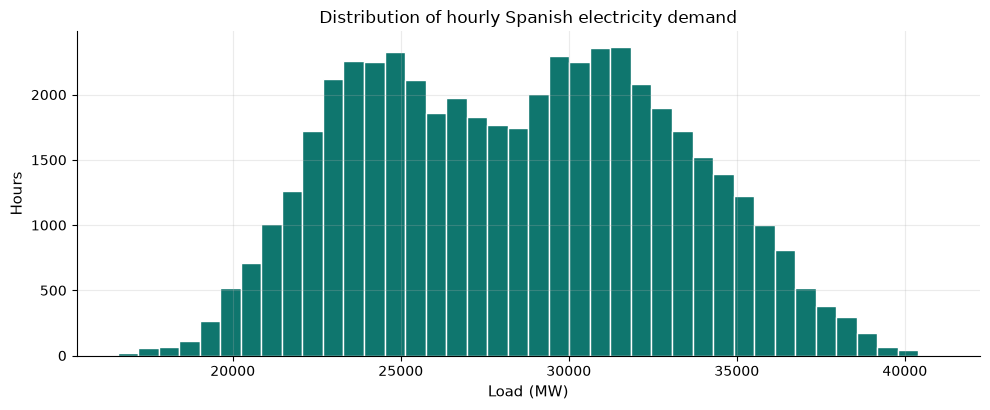

In [3]:
ax = df["load_mw"].plot.hist(bins=40, color=BRAND, edgecolor="white")
ax.set_title("Distribution of hourly Spanish electricity demand")
ax.set_xlabel("Load (MW)")
ax.set_ylabel("Hours")
plt.tight_layout()
plt.show()

### What this means

Demand is unimodal and fairly symmetric around ~28,000 MW. It is not a thin spike, so a “predict the mean every hour” baseline will be mediocre. The left tail (very low load) exists; we will see below that much of it is **nights in spring 2020**, not sensor faults.

## Outliers: statistics vs physics

The 1.5×IQR rule is a screen, not a diagnosis. Extreme hours in energy data are often real (cold evenings, heat waves).

In [4]:
q1 = df["load_mw"].quantile(0.25)
q3 = df["load_mw"].quantile(0.75)
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outside = df["load_mw"].dropna()
n_low = int((outside < low).sum())
n_high = int((outside > high).sum())
print(f"IQR fence: {low:.0f} to {high:.0f} MW")
print(f"Hours below fence: {n_low}")
print(f"Hours above fence: {n_high}")
print()
print("Lowest hours:")
print(df.nsmallest(5, "load_mw")[["local", "load_mw"]].to_string(index=False))
print()
print("Highest hours:")
print(df.nlargest(5, "load_mw")[["local", "load_mw"]].to_string(index=False))

IQR fence: 13468 to 43104 MW
Hours below fence: 0
Hours above fence: 0

Lowest hours:
                    local  load_mw
2020-04-12 05:00:00+02:00  16575.0
2020-04-12 04:00:00+02:00  16594.0
2020-04-05 05:00:00+02:00  16725.0
2020-04-12 07:00:00+02:00  16727.0
2020-04-13 04:00:00+02:00  16779.0

Highest hours:
                    local  load_mw
2017-01-18 20:00:00+01:00  41015.0
2017-01-18 19:00:00+01:00  40939.0
2017-01-19 19:00:00+01:00  40916.0
2017-01-19 20:00:00+01:00  40900.0
2018-02-08 20:00:00+01:00  40693.0


### What this means

**No hour falls outside the IQR fences.** The lowest points are early mornings in **April 2020** (COVID lockdown). The highest points are **winter evenings** (January 2017). Those are plausible human behaviour, not a reason to winsorize the target.

**What could go wrong:** clipping “outliers” here would remove the very peaks a demand model should learn.

## Time-series overview

Plotting 50,000 hourly points is unreadable. Daily mean load shows the trend without hiding 2020.

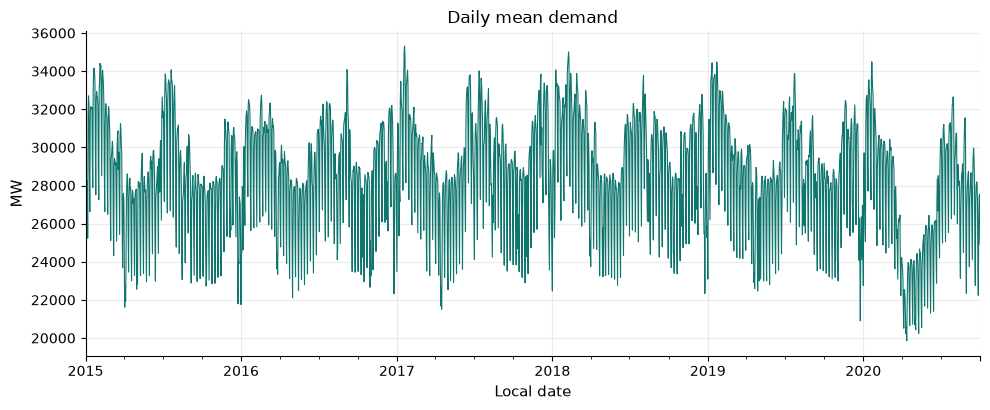

In [5]:
daily = df.set_index("local")["load_mw"].resample("D").mean()
ax = daily.plot(color=BRAND, linewidth=0.8)
ax.set_title("Daily mean demand")
ax.set_xlabel("Local date")
ax.set_ylabel("MW")
plt.tight_layout()
plt.show()

### What this means

You can see a repeating seasonal wave (higher in winter and mid-summer) and a **level drop in spring 2020**. A random shuffle of hours would mix COVID and pre-COVID behaviour into both train and test. Time-series order must be preserved later.

## Daily pattern (hour of day)

Spain’s clock is late compared with many northern European countries. We expect a low night, a morning ramp, and a late evening peak.

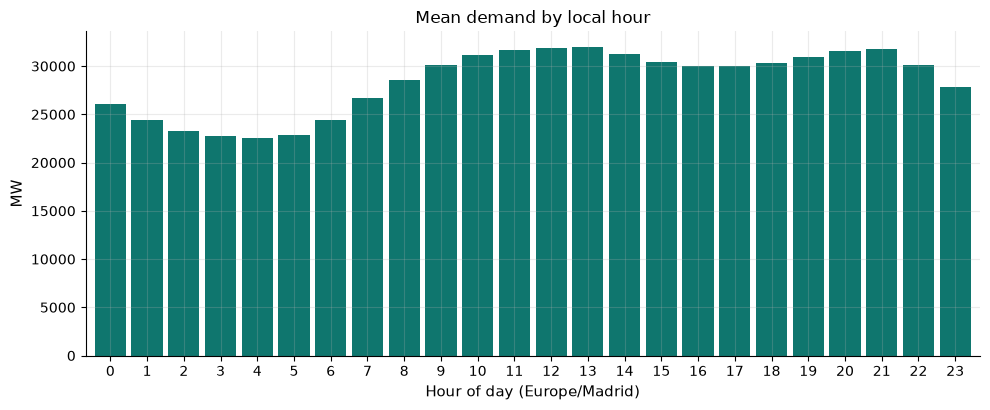

In [6]:
hourly = df.groupby("hour")["load_mw"].mean()
ax = hourly.plot(kind="bar", color=BRAND, width=0.85)
ax.set_title("Mean demand by local hour")
ax.set_xlabel("Hour of day (Europe/Madrid)")
ax.set_ylabel("MW")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

### What this means

- Lowest around **04:00–05:00**.
- Morning ramp from 06:00 to midday.
- A first peak near **13:00**, then a small afternoon dip.
- A second peak around **20:00–21:00**.

That double peak is why `hour` (local) is a strong candidate feature. Using UTC hour would shift this curve and mix winter/summer offsets.

## Weekly pattern

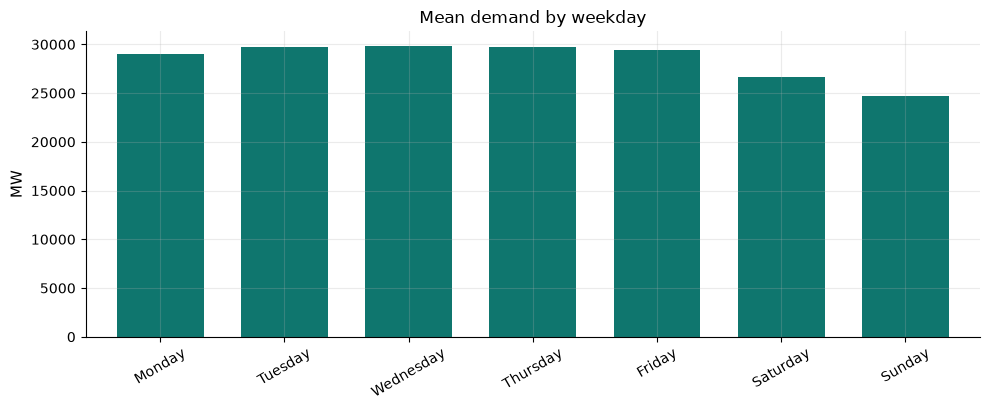

weekday
Monday        97.2% of Wednesday
Tuesday       99.7% of Wednesday
Wednesday    100.0% of Wednesday
Thursday      99.7% of Wednesday
Friday        98.6% of Wednesday
Saturday      89.1% of Wednesday
Sunday        82.8% of Wednesday
Name: load_mw, dtype: str


In [7]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekly = df.groupby("weekday")["load_mw"].mean().reindex(order)
ax = weekly.plot(kind="bar", color=BRAND, width=0.7)
ax.set_title("Mean demand by weekday")
ax.set_xlabel("")
ax.set_ylabel("MW")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
print((weekly / weekly["Wednesday"] * 100).round(1).astype(str) + "% of Wednesday")

### What this means

Weekdays are similar. **Saturday is lower, Sunday is lowest** (about 83% of a typical Wednesday). Industry and offices shutting down is a real effect, so `is_weekend` / `day_of_week` should help. There is little reason to treat Monday as a special extra dummy until residuals say otherwise.

## Monthly / seasonal pattern

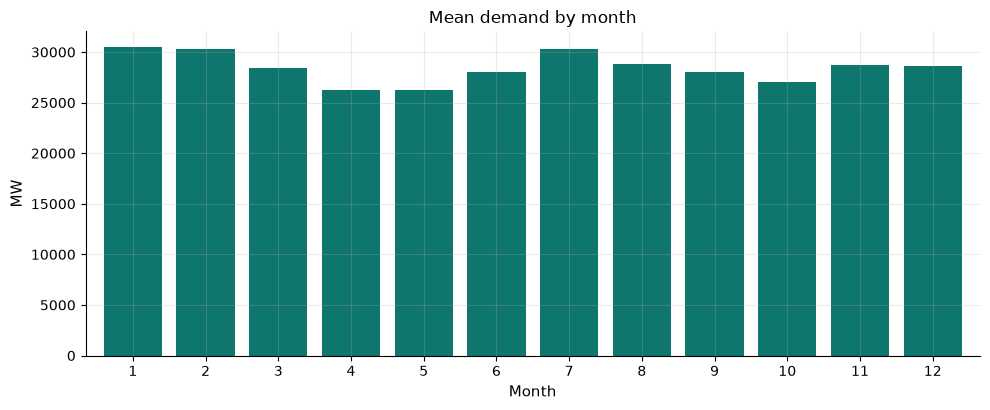

In [8]:
monthly = df.groupby("month")["load_mw"].mean()
ax = monthly.plot(kind="bar", color=BRAND, width=0.8)
ax.set_title("Mean demand by month")
ax.set_xlabel("Month")
ax.set_ylabel("MW")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

### What this means

- **January–February** are high (heating).
- **April–May** are the lowest on average.
- **July** rises again (air conditioning).
- **August** is a bit lower than July — consistent with widespread summer holidays in Spain.

`month` is therefore a reasonable feature. This is still **not** a weather relationship; it is a calendar average that mixes temperature, holidays, and economic activity.

## 2020 vs 2019 (distribution shift)

If 2020 is used as the only test year, we may be testing a different world than we trained on.

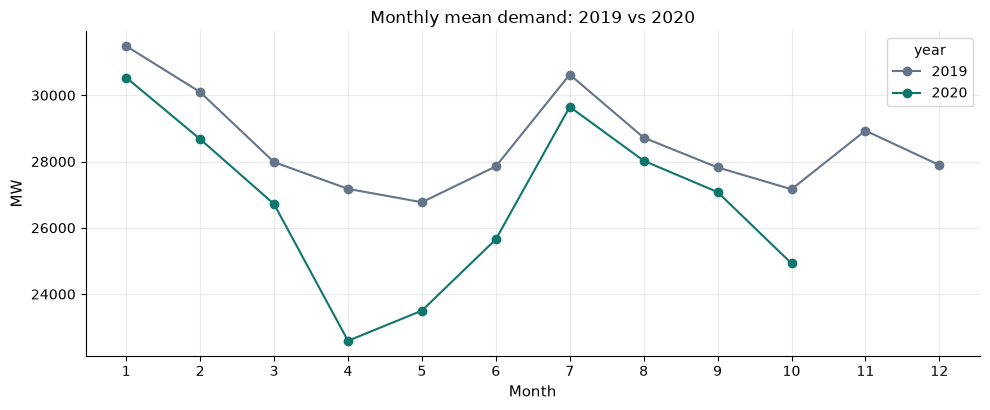

April mean 2019 vs 2020:
year
2019    27176.0
2020    22590.0
Name: 4, dtype: float64


In [9]:
compare = (
    df[df["year"].isin([2019, 2020])]
    .groupby(["month", "year"])["load_mw"]
    .mean()
    .unstack("year")
)
ax = compare.plot(color=["#64748b", BRAND], marker="o")
ax.set_title("Monthly mean demand: 2019 vs 2020")
ax.set_xlabel("Month")
ax.set_ylabel("MW")
ax.set_xticks(range(1, 13))
plt.tight_layout()
plt.show()
print("April mean 2019 vs 2020:")
print(compare.loc[4].round(0))

### What this means

April 2020 is far below April 2019 (lockdown). A fair later split might train through 2018, validate on 2019, and treat 2020 as a **stress test**, not the only proof of accuracy.

We will not drop 2020 from the dataset. We will be honest about it when we evaluate models.

## Time-series behaviour (why lags should help)

If load at 15:00 is close to load at 14:00, yesterday, and last week, then `lag_1`, `lag_24`, and `lag_168` are justified **before** we train anything.

In [10]:
series = df.set_index("utc")["load_mw"]
lag_corr = pd.Series(
    {
        "lag_1 (previous hour)": series.corr(series.shift(1)),
        "lag_24 (same hour yesterday)": series.corr(series.shift(24)),
        "lag_168 (same hour last week)": series.corr(series.shift(168)),
    }
)
print(lag_corr.round(3))

lag_1 (previous hour)            0.956
lag_24 (same hour yesterday)     0.825
lag_168 (same hour last week)    0.904
dtype: float64


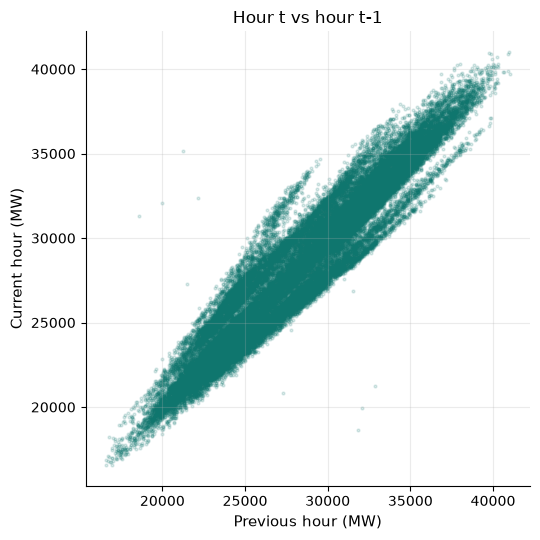

In [11]:
sample = df.dropna(subset=["load_mw"]).copy()
sample["lag_1"] = sample["load_mw"].shift(1)
ax = sample.plot.scatter(
    x="lag_1",
    y="load_mw",
    s=4,
    alpha=0.15,
    color=BRAND,
    figsize=(5.5, 5.5),
)
ax.set_title("Hour t vs hour t-1")
ax.set_xlabel("Previous hour (MW)")
ax.set_ylabel("Current hour (MW)")
plt.tight_layout()
plt.show()

### What this means

Hour-to-hour correlation is very high: demand barely jumps in a single hour. Same-hour-yesterday and same-hour-last-week are also strongly related. That supports the planned lag features.

**What could go wrong:** a naive model that always predicts “same as last hour” will already be hard to beat on MAE. We must keep that **persistence baseline** in Phase 6, or any ML model will look better than it is.

## Weather relationships

The raw file has **no temperature or humidity**. Plotting load against weather now would require inventing numbers or skipping ahead to the Open-Meteo service (Phase 5).

Hypotheses we will test after the join:

- Cold winter hours → higher heating load (we already see high January evenings).
- Hot summer hours → higher cooling load (we already see a July bump).
- Shoulder seasons (April–May) → weaker temperature effect.

Until weather is joined, do not claim that temperature “causes” these calendar patterns. Holidays and COVID can produce the same shape.

## Findings to carry forward

1. **Index:** UTC hourly grid is complete; use local time only for calendar features.
2. **Cleaning:** 23 missing loads; interpolate up to 3 hours; do not fill with 0; do not clip peaks.
3. **Features that look justified:** local hour, weekday/weekend, month, `lag_1`, `lag_24`, `lag_168`.
4. **Baseline:** previous-hour forecast will be strong.
5. **Split:** respect time order; be careful with 2020.
6. **Weather:** wait for Phase 5. No fake weather plots.

Phase 4 will turn the cleaning rules into a reusable Python module. No training yet.